<a href="https://colab.research.google.com/github/naifahamanda/Studi_Kasus_Informatics_Practitioner_Lecture_Series_2026/blob/main/Studi_Kasus_dan_Implementasi_Materi_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Studi Kasus: Klasifikasi Otomatis Faktor Pendorong Utama Deforestasi Menggunakan Citra Satelit & Deep Learning (CNN)**
# 1. Latar Belakang Masalah
Sistem pemantauan hutan berbasis satelit (seperti radar Sentinel-1 dan optik Sentinel-2) mampu mendeteksi peringatan deforestasi (deforestation alerts) secara cepat. Namun, peringatan ini hanya mendeteksi bahwa tutupan pohon telah hilang tanpa menjelaskan penyebab utama (direct drivers) di balik gangguan tersebut.

Mengacu pada materi webinar:

Tantangan Utama: Kehilangan tutupan pohon bisa disebabkan oleh berbagai aktivitas manusia (pertanian skala kecil, pertanian skala besar/industri, pembangunan jalan, pertambangan emas, penebangan kayu/logging) maupun gangguan alamiah (kebakaran hutan, banjir).

Solusi Artificial Intelligence: Model Deep Learning seperti Convolutional Neural Network (CNN) dilatih menggunakan tumpukan citra satelit multispektral/multisensor untuk mengidentifikasi pola spasial, bentuk, ukuran, serta konteks sekitar guna mengklasifikasikan direct driver dari setiap peringatan deforestasi secara otomatis.

# 2. Alur Kerja Sistem (AI & Remote Sensing Workflow)
Penyiapan Data Citra Satelit: Mengintegrasikan kanal citra optik (RGB & NIR) dan citra radar untuk mengekstraksi tekstur serta informasi vegetasi.

Pra-pemrosesan & Ekstraksi Indeks: Menghitung indeks vegetasi (NDVI) dan menyiapkan sampel citra (patch/stack).

Pemodelan CNN (Deep Learning): Melatih arsitektur jaringan saraf konvolusi untuk mengenali pola spasial dari tiap kategori penyebab deforestasi.

Evaluasi & Metrik Kinerja: Mengukur performa klasifikasi menggunakan Overall Accuracy dan Micro F1-Score per kelas pendorong.

In [ ]:
# Install library pendukung
!pip install -q tensorflow matplotlib seaborn scikit-learn numpy pandas

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Set seed agar hasil dapat direproduksi
np.random.seed(42)
tf.random.set_seed(42)

print("✅ TensorFlow & Library Remote Sensing-AI berhasil dimuat!")
print(f"Versi TensorFlow: {tf.__version__}")

✅ TensorFlow & Library Remote Sensing-AI berhasil dimuat!
Versi TensorFlow: 2.21.0


In [ ]:
n_samples = 800
img_height, img_width = 32, 32
n_channels = 6  # 4 Kanal Optik (R, G, B, NIR) + 2 Kanal Radar (VV, VH)

# Kategori Faktor Pendorong Deforestasi (Direct Drivers)
classes = ['Pertanian (Agriculture)', 'Pertambangan (Mining)', 'Jalan/Logging (Roads)', 'Kebakaran Hutan (Wildfire)']
num_classes = len(classes)

# Generasi data sintetis
X_data = np.random.uniform(0.0, 0.4, (n_samples, img_height, img_width, n_channels))
y_labels = np.random.choice(num_classes, size=n_samples)

# Penambahan karakteristik visual/spasial spesifik per kategori
for i in range(n_samples):
    label = y_labels[i]
    if label == 0:   # Pertanian: Nilai NIR sedang, pola blok teratur
        X_data[i, :, :, 3] += 0.35
    elif label == 1: # Pertambangan: Pemantulan tanah terbuka tinggi (RGB terang), NIR rendah
        X_data[i, 10:22, 10:22, :3] += 0.4
    elif label == 2: # Pembangunan Jalan: Pola garis lurus pada kanal radar & optik
        X_data[i, 14:18, :, :] += 0.3
    elif label == 3: # Kebakaran Hutan: Bekas terbakar (NIR sangat rendah, nilai piksel acak)
        X_data[i, :, :, 3] -= 0.15

X_data = np.clip(X_data, 0.0, 1.0)

print(f"✅ Dataset Citra Satelit Sintetis Berhasil Dibuat!")
print(f"   Jumlah Sampel Citra : {X_data.shape[0]}")
print(f"   Dimensi Patch Citra  : {X_data.shape[1]}x{X_data.shape[2]} piksel")
print(f"   Jumlah Kanal Spektral: {X_data.shape[3]} (Optik + Radar)")

✅ Dataset Citra Satelit Sintetis Berhasil Dibuat!
   Jumlah Sampel Citra : 800
   Dimensi Patch Citra  : 32x32 piksel
   Jumlah Kanal Spektral: 6 (Optik + Radar)


In [ ]:
# Pembagian dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

# One-hot encoding untuk target label
y_train_cat = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_cat = tf.keras.utils.to_categorical(y_test, num_classes)

print("✅ Preprocessing & Splitting Selesai:")
print(f"   Data Latih (Training Set) : {X_train.shape[0]} sampel")
print(f"   Data Uji (Testing Set)   : {X_test.shape[0]} sampel")

✅ Preprocessing & Splitting Selesai:
   Data Latih (Training Set) : 640 sampel
   Data Uji (Testing Set)   : 160 sampel


In [ ]:
def build_deforestation_cnn(input_shape, num_classes):
    model = models.Sequential([
        # Layer Konvolusi 1 & Pooling
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Layer Konvolusi 2 & Pooling
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Dense / Fully Connected Layers
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation='softmax')
    ])
    return model

# Inisialisasi dan kompilasi model
cnn_model = build_deforestation_cnn((img_height, img_width, n_channels), num_classes)
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,572 (2.08 MB)

 Trainable params: 545,380 (2.08 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
# Pelatihan Model CNN
epochs = 15
batch_size = 32

print("🚀 Memulai Pelatihan Model CNN Klasifikasi Deforestasi...")
history = cnn_model.fit(
    X_train, y_train_cat,
    validation_data=(X_test, y_test_cat),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
print("✅ Pelatihan Model Selesai!")

🚀 Memulai Pelatihan Model CNN Klasifikasi Deforestasi...
Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 130ms/step - accuracy: 0.9359 - loss: 0.2496 - val_accuracy: 0.7750 - val_loss: 0.7596
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 1.0000 - loss: 2.3985e-04 - val_accuracy: 0.7750 - val_loss: 0.4464
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - accuracy: 1.0000 - loss: 6.8970e-05 - val_accuracy: 0.7875 - val_loss: 0.4161
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 1.0000 - loss: 1.2052e-05 - val_accuracy: 0.7563 - val_loss: 0.5431
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 1.0000 - loss: 3.4866e-05 - val_accuracy: 0.4875 - val_loss: 0.6935
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 1.0000 - loss: 2.6970e-07 - val_accuracy: 0.4875 - val_loss: 0.8156
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 109ms/step - accuracy: 1.0000 - loss: 2.4717e-07 - val_accuracy: 0.4875 - val_loss: 0.8474
Epoch 8/15
20/20 ━━━━━━━━━━

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
📊 --- EVALUASI MODEL KLASIFIKASI FAKTOR DEFORESTASI ---
Micro F1-Score: 1.0000

Laporan Klasifikasi Detail:
                            precision    recall  f1-score   support

   Pertanian (Agriculture)       1.00      1.00      1.00        45
     Pertambangan (Mining)       1.00      1.00      1.00        42
     Jalan/Logging (Roads)       1.00      1.00      1.00        37
Kebakaran Hutan (Wildfire)       1.00      1.00      1.00        36

                  accuracy                           1.00       160
                 macro avg       1.00      1.00      1.00       160
              weighted avg       1.00      1.00      1.00       160



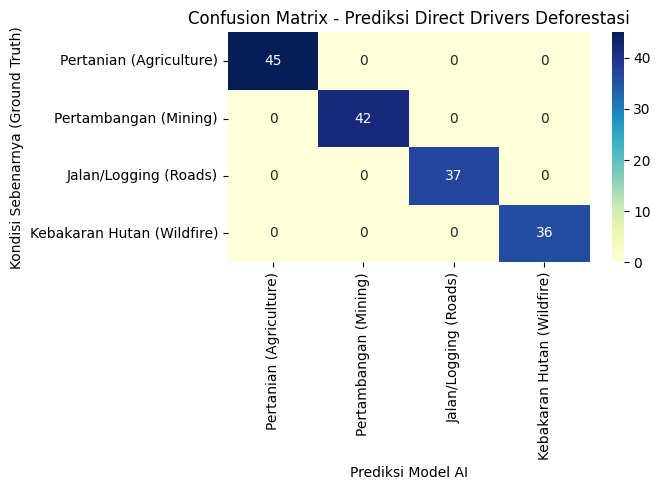

In [ ]:
# Prediksi pada Data Uji
y_pred_prob = cnn_model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

# Perhitungan Metrik Evaluasi
micro_f1 = f1_score(y_test, y_pred, average='micro')
print("📊 --- EVALUASI MODEL KLASIFIKASI FAKTOR DEFORESTASI ---")
print(f"Micro F1-Score: {micro_f1:.4f}\n")
print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=classes))

# Visualisasi Confusion Matrix
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix - Prediksi Direct Drivers Deforestasi')
plt.xlabel('Prediksi Model AI')
plt.ylabel('Kondisi Sebenarnya (Ground Truth)')
plt.tight_layout()
plt.show()

In [ ]:
def classify_new_alert(sample_index):
    sample_img = X_test[sample_index:sample_index+1]
    true_label = classes[y_test[sample_index]]

    pred_prob = cnn_model.predict(sample_img)[0]
    pred_class_idx = np.argmax(pred_prob)
    pred_label = classes[pred_class_idx]
    confidence = pred_prob[pred_class_idx] * 100

    print(f"🔍 --- HASIL DETEKSI PERINGATAN DEFORESTASI SAMPEL #{sample_index} ---")
    print(f"Faktor Sebenarnya (Ground Truth) : {true_label}")
    print(f"Hasil Klasifikasi Model AI      : {pred_label}")
    print(f"Tingkat Kepercayaan (Confidence): {confidence:.2f}%")

    # Preskripsi Tindakan Intervensi Lapangan
    print("\n💡 Rekomendasi Tindakan:")
    if pred_label == 'Pertambangan (Mining)':
        print("   -> Kirim tim patroli hukum ke lokasi untuk verifikasi izin konsesi tambang.")
    elif pred_label == 'Jalan/Logging (Roads)':
        print("   -> Pantau pembukaan jalan baru untuk mencegah perambahan hutan lebih lanjut.")
    elif pred_label == 'Kebakaran Hutan (Wildfire)':
        print("   -> Kerahkan tim pemadam kebakaran dan cek titik panas (hotspot).")
    else:
        print("   -> Evaluasi status kepemilikan lahan dan tutupan vegetasi secara berkala.")

# Jalankan simulasi untuk salah satu sampel
classify_new_alert(sample_index=5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
🔍 --- HASIL DETEKSI PERINGATAN DEFORESTASI SAMPEL #5 ---
Faktor Sebenarnya (Ground Truth) : Pertambangan (Mining)
Hasil Klasifikasi Model AI      : Pertambangan (Mining)
Tingkat Kepercayaan (Confidence): 100.00%

💡 Rekomendasi Tindakan:
   -> Kirim tim patroli hukum ke lokasi untuk verifikasi izin konsesi tambang.
